# What our data is about:
Solvability measures how much of a compound can dissolve in water at a given pH and temperature, directly dictating a drug's oral bioavailability and absorption potential. Poor solubility limits how fast a drug can dissolve in gastrointestinal tract, impacting drug's performance and usefulness. Some low-solubility compounds can require specialized formulation strategies, to target specific delivery sytem in the organism that we want to achieve.

We have a lot of continous and binary features, as will be shown in EDA below. Our best guess for their meaning is that we have normalized 1D/2D Molecular Descriptors - structural properties calculated by chemical libraries. 

We have 48 binary features representing structural fingerprints like the presence or absence of specific rings, bonds, or functional groups 
and 248 continuous features representing global physical properties like molecular weight, total polar surface area, or lipophilicity.


Knowing we are working with ADMET property and molecular descriptors, we will approach the data with caution, knowing that some features may be extremly important, while being an outlier for example.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotx
import seaborn as sns
import plotly.express as px
import umap
import optuna

from scipy.stats import f_oneway
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from catboost import CatBoostRegressor

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

style = matplotx.styles.gruvbox["light"]
plt.style.use(style)
# plt.rcParams.update({
#     "figure.facecolor": "white",  # outside the axes
#     "axes.facecolor": "white",    # plot area
#     "savefig.facecolor": "white", # saved images
# })


from sklearn.metrics import root_mean_squared_error, make_scorer
from sklearn.compose import ColumnTransformer
import xgboost as xgb
import lightgbm as lgb
from IPython.display import display
import warnings

# EDA

In [2]:

training_data = pd.read_csv("../../challenge/TrainingData_Blinded.csv", header=0, index_col="Name")
test_df = pd.read_csv("../../challenge/TestData_Blinded_NoY.csv", header=0, index_col="Name")


training_data.rename(columns={'Y': 'target'}, inplace=True)
X = training_data.drop(columns=["target"]).copy()
y = training_data["target"]

print("Dataset shape:", training_data.shape)
print("Number of classes:", y.nunique())

training_data.head()

Dataset shape: (1087, 296)
Number of classes: 338


,target,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X330,X331,X332,X333,X334,X335,X336,X337,X338,X339
Name,,,,,,,,,,,,,,,,,,,,,
Y1,-0.085199,0.309546,0.755618,0.0,0.029666,0.128079,0,0.0,0.098216,0.062834,...,0.000,0.000000,0,0.000000,0.159079,0.0,0,0.000000,0,0.0
Y2,-0.353311,0.288419,0.528816,0.0,0.090244,0.069176,0,0.0,0.102855,0.081353,...,0.125,0.000000,0,0.077361,0.102335,0.0,0,0.000000,0,0.0
Y3,0.933576,0.419655,0.775678,0.0,0.147795,0.231356,0,0.0,0.192243,0.102755,...,0.000,0.000000,0,0.941991,0.266956,0.0,0,0.000000,0,0.0
Y5,0.071583,0.455953,0.621974,0.0,0.016421,0.042072,0,0.0,0.067610,0.046155,...,0.000,0.248861,0,0.202801,0.079247,0.0,0,0.333333,0,0.0
Y6,-0.389871,0.328753,0.569900,0.0,0.150318,0.040787,1,0.0,0.132359,0.083607,...,0.250,0.237481,0,0.124486,0.121555,0.0,0,0.000000,0,0.0


In [3]:
training_data.describe()

,target,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X330,X331,X332,X333,X334,X335,X336,X337,X338,X339
count,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,...,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000
mean,0.004513,0.324930,0.598499,0.004600,0.092906,0.096465,0.023919,0.007820,0.132674,0.092115,...,0.050943,0.056610,0.027599,0.134391,0.155980,0.009972,0.004600,0.016559,0.031279,0.002883
std,0.315469,0.127109,0.112948,0.052357,0.101186,0.113275,0.152867,0.072343,0.088995,0.084020,...,0.098945,0.136687,0.163896,0.176417,0.103498,0.062025,0.067697,0.086610,0.174150,0.041849
min,-0.713205,0.000000,-0.045405,0.000000,0.000000,0.000000,0.000000,0.000000,0.006862,0.000000,...,0.000000,-0.007090,0.000000,-0.001502,0.004104,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-0.256138,0.248555,0.540171,0.000000,0.028135,0.020824,0.000000,0.000000,0.083894,0.046002,...,0.000000,0.000000,0.000000,0.000000,0.095754,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-0.022415,0.303300,0.608965,0.000000,0.066682,0.072494,0.000000,0.000000,0.112968,0.077890,...,0.000000,0.000000,0.000000,0.049144,0.135002,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.212094,0.369575,0.668921,0.000000,0.134380,0.131796,0.000000,0.000000,0.149047,0.112930,...,0.125000,0.000000,0.000000,0.227662,0.177760,0.000000,0.000000,0.000000,0.000000,0.000000
max,0.950096,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


We can see that the values are normalized in some way, either using min-max scaler or z-score scaler. We are suspecting that the dataset was scaled based on some larger chemical dataset. This way the properties of the compounds are preserved and the model is not biased to the subset chosen for training, but represent larger group of compounds and chemical properties. 

In [4]:
# 1. Missing Values Analysis
missing_counts = X.isnull().sum()
total_missing = missing_counts.sum()
print(f"Total missing values in dataset: {total_missing}")

if total_missing > 0:
    missing_features = missing_counts[missing_counts > 0].sort_values(ascending=False)
    plt.figure(figsize=(10, 4))
    sns.barplot(x=missing_features.index, y=missing_features.values, color="salmon")
    plt.title("Missing Values per Feature")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=90)
    plt.show()

Total missing values in dataset: 0


In [5]:
stats = pd.DataFrame({
    "mean": training_data.mean(),
    "median": training_data.median(),
    "mode": training_data.mode().iloc[0],
    "range": training_data.max() - training_data.min(),
    "std": training_data.std(),
    "cv": training_data.std() / training_data.mean(),
    "iqr": training_data.quantile(0.75) - training_data.quantile(0.25),
    "skewness": training_data.skew(),
    "kurtosis": training_data.kurt()
})

stats

,mean,median,mode,range,std,cv,iqr,skewness,kurtosis
target,0.004513,-0.022415,0.020277,1.663301,0.315469,69.908689,0.468232,0.425750,-0.396715
X1,0.324930,0.303300,0.000000,1.000000,0.127109,0.391190,0.121020,1.269164,5.001758
X2,0.598499,0.608965,0.703054,1.045405,0.112948,0.188718,0.128750,-0.439118,0.922465
X3,0.004600,0.000000,0.000000,1.000000,0.052357,11.382407,0.000000,12.590393,177.330019
X4,0.092906,0.066682,0.000000,1.000000,0.101186,1.089126,0.106245,3.130676,16.982691
...,...,...,...,...,...,...,...,...,...
X335,0.009972,0.000000,0.000000,1.000000,0.062025,6.219761,0.000000,8.207443,87.460925
X336,0.004600,0.000000,0.000000,1.000000,0.067697,14.717312,0.000000,14.662804,213.390429
X337,0.016559,0.000000,0.000000,1.000000,0.086610,5.230273,0.000000,6.044707,41.698307
X338,0.031279,0.000000,0.000000,1.000000,0.174150,5.567684,0.000000,5.392877,27.133038


## Understanding target variable

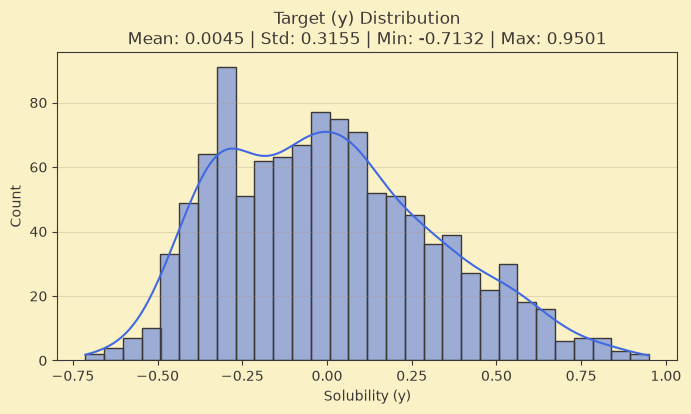

In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(y, kde=True, bins=30, color='royalblue')
plt.title(f"Target (y) Distribution\nMean: {y.mean():.4f} | Std: {y.std():.4f} | Min: {y.min():.4f} | Max: {y.max():.4f}")
plt.xlabel("Solubility (y)")
plt.ylabel("Count")
plt.grid(axis='y', alpha=0.3)
plt.show()

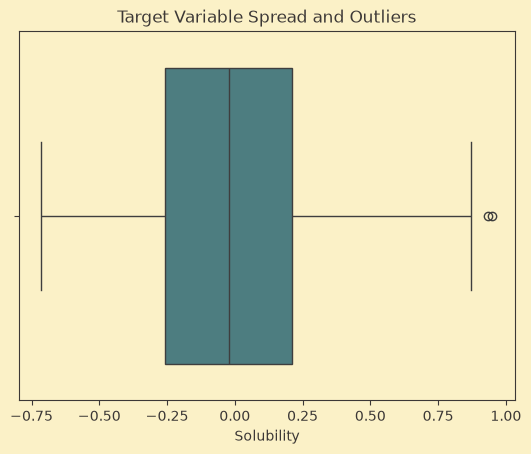

In [7]:
sns.boxplot(x=training_data['target'])
plt.title("Target Variable Spread and Outliers")
plt.xlabel("Solubility")
plt.show()

Based on the histogram, kernel density estimation, boxplot and the statistics calculated above, we can see that the target variable has small right skew (0.42) and kurtosis (-0.40). It follows from the bimodal distribution that we observe. The distribution focuses on values around -0.3 and 0.0. This means we have mostly weak solubility and ok solubility. We do not have a clear distinction between soluble and insoluble compounds(We are assuming that ~0.0 - ~0.2 does not indicate strong solubillity). We do not have many stong outliers. 

The valley between binomial peaks would be a problem for normal ML models like trees, as they would safely fall into the values between the peaks, minimizing the error. Fortunately, boosting algorithms should tune to the residuals, making predictions better. 

## Understanding the features

In [8]:
unique_counts = X.nunique()
binary_features = unique_counts[unique_counts <= 2].index.tolist()
continuous_features = unique_counts[unique_counts > 2].index.tolist()

print(f"Detected {len(binary_features)} binary features (likely fingerprints).")
print(f"Detected {len(continuous_features)} continuous features (likely normalized descriptors).")

Detected 48 binary features (likely fingerprints).
Detected 247 continuous features (likely normalized descriptors).


This shows us that we have 48 features that are likely chemical flags (0/1) that show some property. Majority of features are continous, likely being a molecular descriptors like mass or polar surface. 

This is a great dataset for trees (and all their boosting varieties), which can first decide on binary features and then set thresholds for continous features.

In [9]:
total_features = len(X.columns)
unique_counts = X.nunique()

binary_features = unique_counts[unique_counts <= 2].index.tolist()
discrete_features = unique_counts[(unique_counts > 2) & (unique_counts <= 15)].index.tolist()
continuous_features = unique_counts[unique_counts > 15].index.tolist()

bin_pct = (len(binary_features) / total_features) * 100
dis_pct = (len(discrete_features) / total_features) * 100
cont_pct = (len(continuous_features) / total_features) * 100

# Print results
print(f"Binary features:     {len(binary_features)} ({bin_pct:.1f}%)")
print(f"Discrete features: {len(discrete_features)} ({dis_pct:.1f}%)")
print(f"Continuous features:  {len(continuous_features)} ({cont_pct:.1f}%)")

Binary features:     48 (16.3%)
Discrete features: 60 (20.3%)
Continuous features:  187 (63.4%)


We are working with a whole variety of numbers in the features. Some are binary, providing clear chemical answers. Majority of the features have above 15 unique values, so we categorize them as continous. Around 20% of features have less than 15 distinct values, which we categorize as discrete. They may be continous really, but have so little different readings that we treat them as discrete.

## Outlier analysis:

In [10]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1

outliers = (X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))

outliers.sum().sort_values(ascending=False)
print("Total number of outlier values:", outliers.sum().sum())
print("Bottles (rows) containing outliers:", outliers.any(axis=1).sum())

Total number of outlier values: 19080
Bottles (rows) containing outliers: 1086


We can see that a lot of the data can be considered an outlier if using the traditional definition of outlier being below 1st and over 3rd quartile. Yet, for cheminformatics data we will say that those are important values and we will want to preserve them. Values of molecular descriptors are messy, often sparse and even a little bit of infomation that looks like an outlier can prove to be critical from chemistry perspective. 
We wanted to perform more advanced analysis of the outliers:

#### Isolation forest & PCA with Mahalanobis distance for outlier detection

PCA with Mahalanobis finds the mathematical center of the entire dataset and measures the distance of each point from that center, flagging chemicals that break the overall correlation patterns of the group. 

Isolation Forest works by making random cuts across the features to see how quickly a single data point gets separated from the rest; rare chemical profiles get isolated in just a few cuts, while normal ones require many. 

In [11]:
anomaly_fraction = 0.05 

# Isolation forest
iso_forest = IsolationForest(contamination=anomaly_fraction, random_state=42)
iso_labels = iso_forest.fit_predict(X)
iso_outliers = (iso_labels == -1)


# PCA + Mahalanobis
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f"Reduced from {X.shape[1]} features to {X_pca.shape[1]} principal components.")

mahalanobis_sq = np.sum((X_pca ** 2) / pca.explained_variance_, axis=1)
mah_threshold = np.percentile(mahalanobis_sq, (1 - anomaly_fraction) * 100)
pca_outliers = (mahalanobis_sq > mah_threshold)



results = pd.DataFrame({
    'Target_Value': y,
    'IsoForest_Flag': iso_outliers,
    'PCA_Mahalanobis_Flag': pca_outliers,
    'Mahalanobis_Score': mahalanobis_sq
}, index=training_data.index)

results['High_Confidence_Anomaly'] = results['IsoForest_Flag'] & results['PCA_Mahalanobis_Flag']
strong_anomalies = results[results['High_Confidence_Anomaly'] == True]

print(f"Total samples: {len(training_data)}")
print(f"Flagged by Isolation Forest: {iso_outliers.sum()}")
print(f"Flagged by PCA+Mahalanobis: {pca_outliers.sum()}")
print(f"Flagged by BOTH (Intersection): {len(strong_anomalies)}")

print("\nTop High-Confidence Anomalies (Sorted by distance):")
display(strong_anomalies.sort_values(by='Mahalanobis_Score', ascending=False).head(10))

Reduced from 295 features to 73 principal components.
Total samples: 1087
Flagged by Isolation Forest: 55
Flagged by PCA+Mahalanobis: 55
Flagged by BOTH (Intersection): 13

Top High-Confidence Anomalies (Sorted by distance):


,Target_Value,IsoForest_Flag,PCA_Mahalanobis_Flag,Mahalanobis_Score,High_Confidence_Anomaly
Name,,,,,
Y822,0.477376,True,True,1067.916475,True
Y736,-0.312665,True,True,690.242489,True
Y725,-0.131090,True,True,634.385146,True
Y1306,-0.646009,True,True,421.836374,True
Y928,-0.278553,True,True,410.739119,True
Y1074,-0.179550,True,True,409.596370,True
Y1009,-0.364813,True,True,400.200725,True
Y898,-0.147463,True,True,335.022762,True
Y506,-0.342399,True,True,298.489884,True


We have possible 13 rows that can be outliers.

## Checking impact of features
We have a lot of features - we want to check if all of them are significant for prediction.

Found 172 features with variance < 0.01.


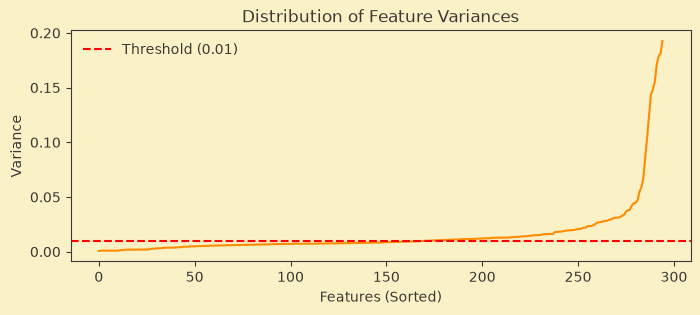

In [12]:
variances = X.var()
low_variance_threshold = 0.01
low_var_features = variances[variances < low_variance_threshold].index.tolist()
print(f"Found {len(low_var_features)} features with variance < {low_variance_threshold}.")

plt.figure(figsize=(8, 3))
plt.plot(sorted(variances.values), color='darkorange')
plt.axhline(y=low_variance_threshold, color='red', linestyle='--', label='Threshold (0.01)')
plt.title("Distribution of Feature Variances")
plt.ylabel("Variance")
plt.xlabel("Features (Sorted)")
plt.legend()
plt.show()

In [13]:
variances = X.var()
low_var_features = variances[variances < 0.01].index

# ANOVA test
important_low_var = []
for col in low_var_features:
    mask_0 = (X[col] == 0).values
    mask_1 = (X[col] != 0).values
    
    group_0 = y[mask_0]
    group_1 = y[mask_1]
    
    if len(group_1) > 2 and len(group_0) > 2: 
        f_stat, p_val = f_oneway(group_0, group_1)
        if p_val < 0.05:
            important_low_var.append(col)


print(f"Low variance features: {len(low_var_features)}")
print(f"Features with low varaince that have STRONG imapct on solubility (target): {len(important_low_var)}")


Low variance features: 172
Features with low varaince that have STRONG imapct on solubility (target): 43


In theory, low variance features could be subject to deletion. However, in cheminformatics, those values could mark very important characteristics of a compound. 
We performed ANOVA analysis to test which features are really important for solubility prediction. 

43 features are VERY important for solubility. They are rare, have low variance, but if they are present, they impact prediction. 

129 features don't show impact on solubility and theoretically could be dropped.

#### Checking how many features are highly correlated with the target
And how many of the low variance features are highly correlated with the target

Top 10% Correlation Threshold Value: 0.2252
Number of ANOVA features in the top 10% highest correlation: 8 (out of 43)



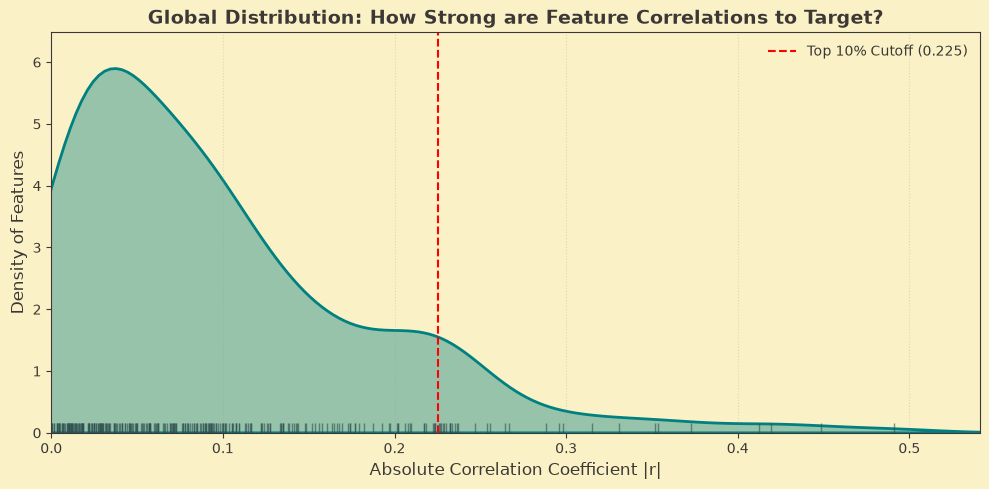

Correlation Strength Breakdown:
Strong Correlation (> 0.5):   0 features
Moderate Correlation (0.3-0.5): 9 features
Weak Correlation (< 0.3):     286 features


In [14]:
correlations = X.corrwith(y).abs()

top_10_percent_cutoff = correlations.quantile(0.90)
top_10_percent_features = correlations[correlations >= top_10_percent_cutoff].index

anova_in_top_10 = [col for col in important_low_var if col in top_10_percent_features]

print(f"Top 10% Correlation Threshold Value: {top_10_percent_cutoff:.4f}")
print(f"Number of ANOVA features in the top 10% highest correlation: {len(anova_in_top_10)} (out of {len(important_low_var)})\n")

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(correlations, fill=True, color="teal", alpha=0.4, linewidth=2, ax=ax)
sns.rugplot(correlations, color="darkslategrey", alpha=0.6, ax=ax)

ax.axvline(top_10_percent_cutoff, color="red", linestyle="--", linewidth=1.5, 
           label=f"Top 10% Cutoff ({top_10_percent_cutoff:.3f})")
ax.set_title("Global Distribution: How Strong are Feature Correlations to Target?", fontsize=14, fontweight='bold')
ax.set_xlabel("Absolute Correlation Coefficient |r|", fontsize=12)
ax.set_ylabel("Density of Features", fontsize=12)
ax.set_xlim(0, correlations.max() + 0.05)
ax.grid(axis='x', alpha=0.3, linestyle=':')
ax.legend()

plt.tight_layout()
plt.show()

print("Correlation Strength Breakdown:")
print(f"Strong Correlation (> 0.5):   {sum(correlations > 0.5)} features")
print(f"Moderate Correlation (0.3-0.5): {sum((correlations >= 0.3) & (correlations <= 0.5))} features")
print(f"Weak Correlation (< 0.3):     {sum(correlations < 0.3)} features")


As we can see, we do not have a lot of strongly correlated features with respect to the target (solubility). That means that the solubility is based on complex function of the features rather than straighforward explanation of solubility with some feature. 

#### Futher check of correlation with the target

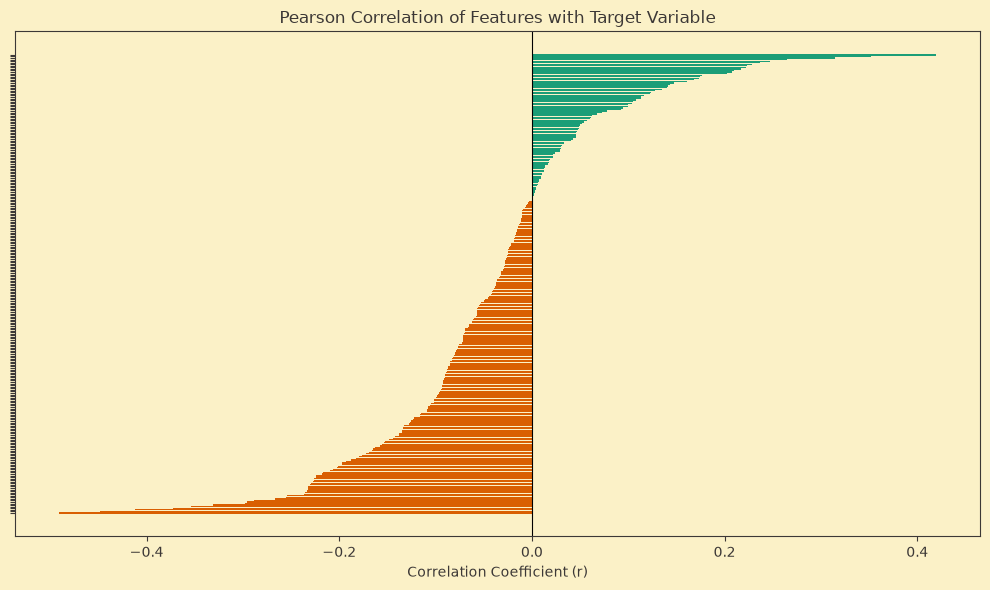

In [15]:
target_corr = X.corrwith(y).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#d95f02" if val < 0 else "#1b9e77" for val in target_corr.values]
bars = ax.barh(target_corr.index, target_corr.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
# ax.set_xlim(-1.0, 0.7)
ax.set_yticklabels("")
# ax.set_xticklabels("")
ax.set_title("Pearson Correlation of Features with Target Variable")
ax.set_xlabel("Correlation Coefficient (r)")
for bar in bars:
    w = bar.get_width()
    offset = 0.02 if w >= 0 else -0.08
plt.tight_layout()
plt.show()

The majority of the features have negative correlation, meaning that the higher the value, the lower the solubility. 
Majority of the features have weak correlation, meaning that they do not impact directly the solubility by themselves. As said before, it seems that solubility is complex function of the features.

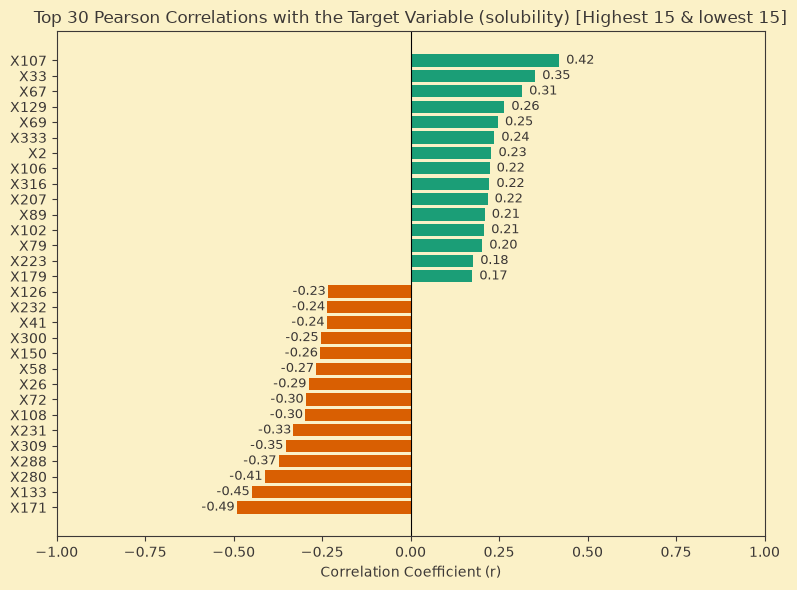

In [16]:
top_negative = target_corr.head(15)
top_positive = target_corr.tail(15)
filtered_corr = pd.concat([top_negative, top_positive])

fig, ax = plt.subplots(figsize=(8,6)) 
colors = ["#d95f02" if val < 0 else "#1b9e77" for val in filtered_corr.values]
bars = ax.barh(filtered_corr.index, filtered_corr.values, color=colors)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(-1.0, 1.0)
ax.set_title("Top 30 Pearson Correlations with the Target Variable (solubility) [Highest 15 & lowest 15]")
ax.set_xlabel("Correlation Coefficient (r)")

for bar in bars:
    w = bar.get_width()
    offset = 0.02 if w >= 0 else -0.10
    ax.text(w + offset, bar.get_y() + bar.get_height() / 2, f"{w:.2f}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

#### More in depth analysis of top correlating features:

Found 30 Top 10% features.


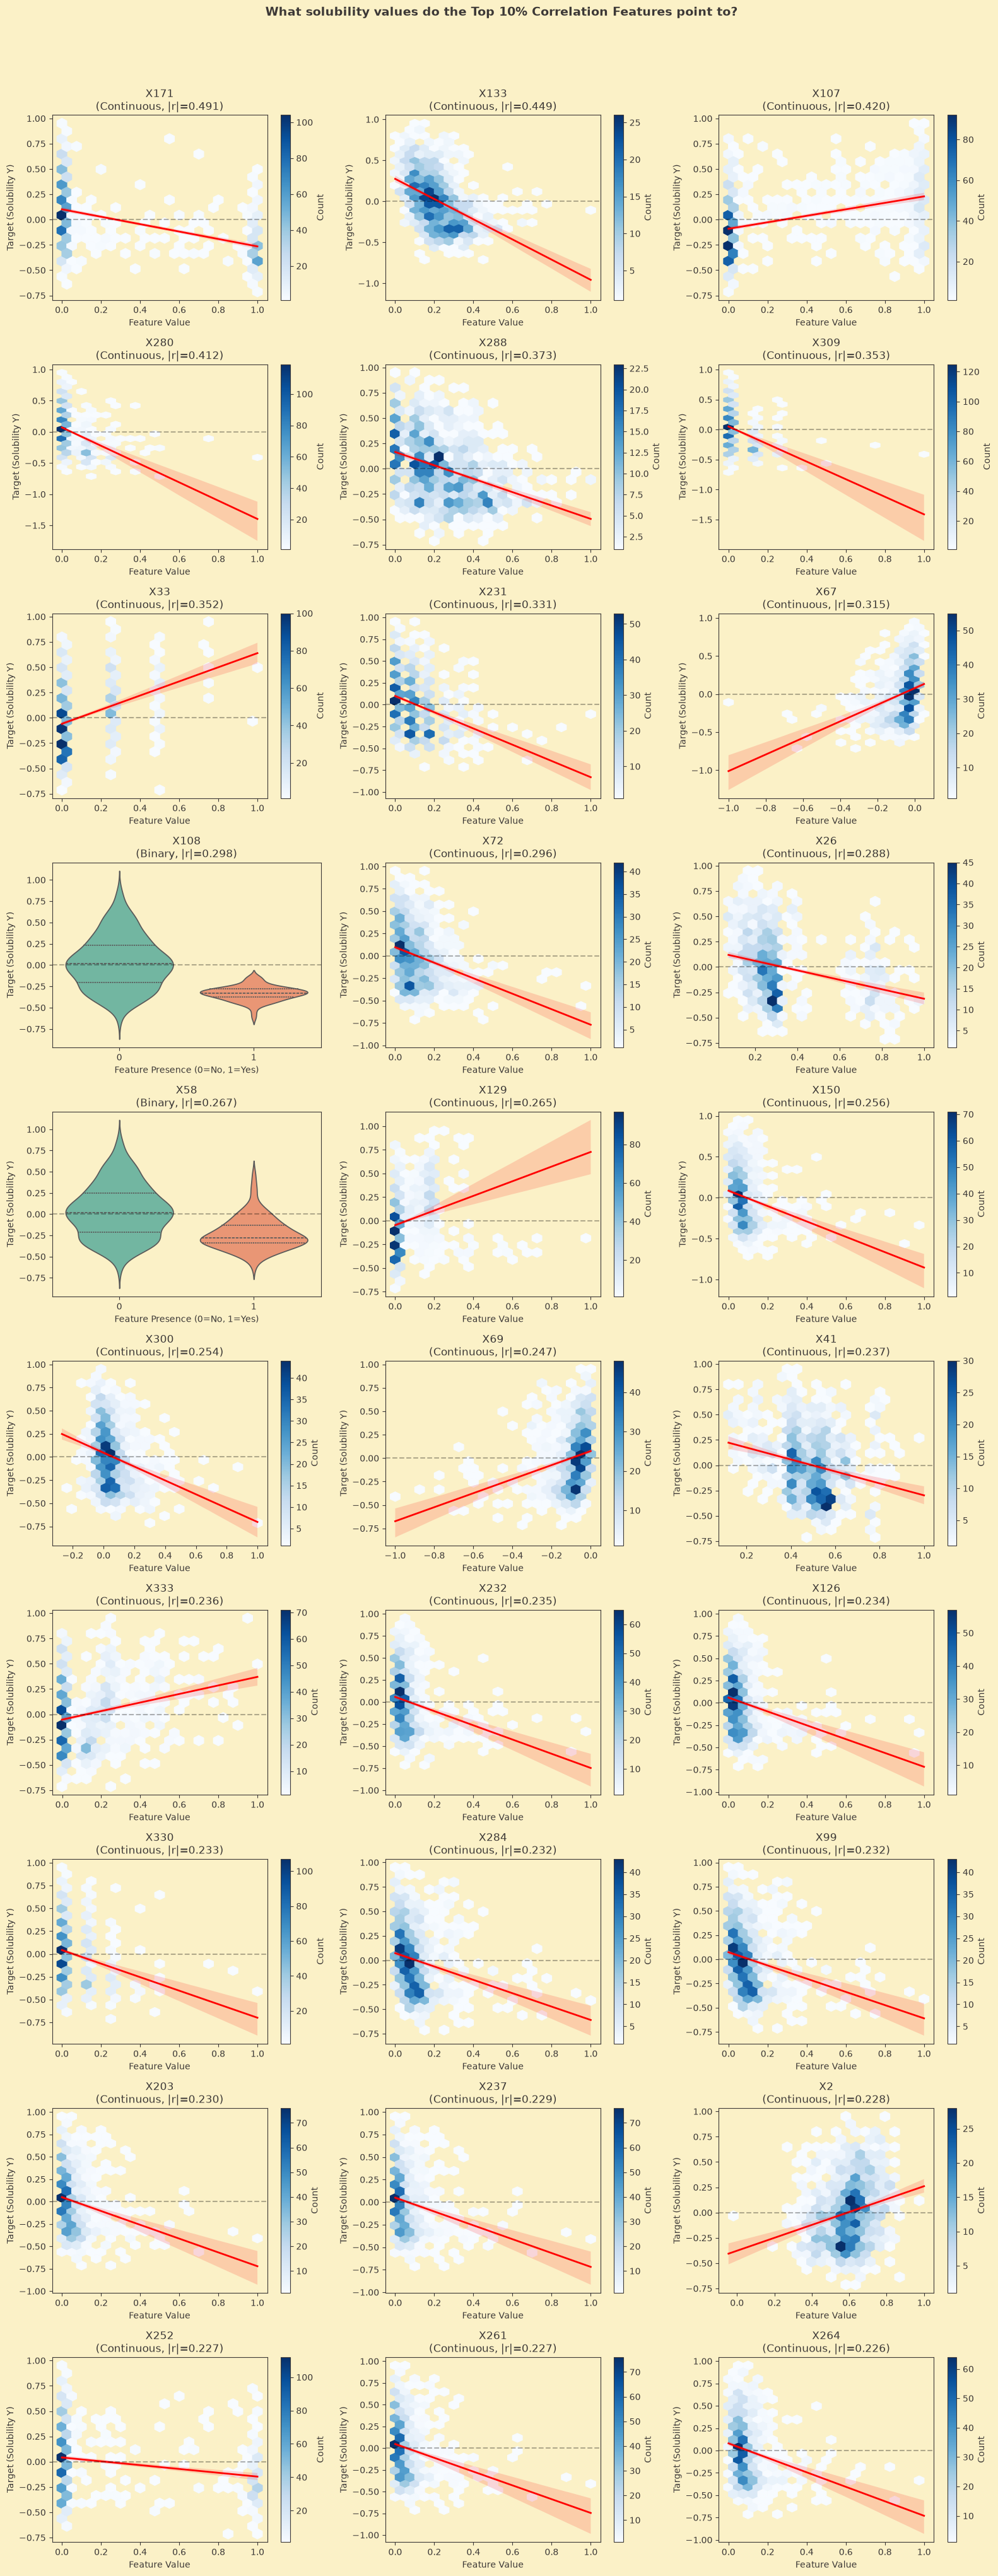

In [17]:
top_10_cols = top_10_percent_features.tolist()

print(f"Found {len(top_10_cols)} Top 10% features.")

def analyze_feature_target_mapping(feature_list, group_name, num_to_plot=30):
    sorted_features = correlations[feature_list].sort_values(ascending=False).index[:num_to_plot]
    
    fig, axes = plt.subplots(10, 3, figsize=(16,40))
    fig.suptitle(f"What solubility values do the {group_name} Features point to?", fontsize=14, fontweight='bold', y=1.02)
    axes = axes.flatten()
    
    for i, col in enumerate(sorted_features):
        ax = axes[i]
        
        is_binary = X[col].nunique() <= 2
        
        if is_binary:
            sns.violinplot(x=X[col], y=y, hue=X[col], ax=ax, palette="Set2", inner="quartile", legend=False)
            ax.set_title(f"{col}\n(Binary, |r|={correlations[col]:.3f})")
            ax.set_xlabel("Feature Presence (0=No, 1=Yes)")
        else:
            hb = ax.hexbin(X[col], y, gridsize=20, cmap="Blues", mincnt=1)
            fig.colorbar(hb, ax=ax, label='Count')
            sns.regplot(x=X[col], y=y, ax=ax, scatter=False, color="red", line_kws={"linewidth": 2})
            ax.set_title(f"{col}\n(Continuous, |r|={correlations[col]:.3f})")
            ax.set_xlabel("Feature Value")
            
        ax.set_ylabel("Target (Solubility Y)")
        ax.axhline(0, color='black', linestyle='--', alpha=0.3) # Reference line at Y=0

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

analyze_feature_target_mapping(top_10_cols, "Top 10% Correlation")

In [18]:
training_data['X33'].unique()

array([0.  , 0.75, 0.25, 0.5 , 1.  ])

As we can see the correlation directions are mixed. While all these features are in the top 10% for absolute correlation strength ($\vert{}r\vert{}$ ranging from 0.226 to 0.491), they affect the target (solubility) differently.

Features like X171, X133, X280, X288, X309, X231, X310, X20, X158, X302, X31, X173, X126, X226, X187, X88, X203, X112, X262, X241, and X264 have a negative correlation (red line slopes down, meaning higher feature values predict lower solubility).

On the other side, features X107, X33, X67, X120, X42, X111, and X2 have a positive correlation (higher values predict higher solubility).

The density hexbins show that for almost all these "top" continuous features, the vast majority of molecules have a feature value at or very near 0.0.

Because most data is clustered near zero, the strong correlation slopes are largely driven by a smaller subset of molecules that actually possess higher values for these features. When these rare higher values occur, they drastically shift the predicted solubility.

We can also observe 'bands' of values in some of the features. That would mean that the values are not continous, but have some specific values eg.for X33 we have array([0.  , 0.75, 0.25, 0.5 , 1.  ]). This may be a reason to differently treat those values in preprocessing. This banding is also very distinct in X20, X226, and X203.

For X171 we can clearly see that higher values correspond to worse solubility. The same can be deducted in X133, X282, X231, X310, X158, X302, X173, X126, X187, X88, X112, and X241 just by looking at the hexbins. Hhigher feature values hexbins are below the group of the hexbins that are around 0.0 solubility for most.

There are also two binary features, X108 and X58, represented by violin plots. For both of these features, the vast majority of molecules have a value of 0, which is centered near a solubility of 0.0. The much smaller group of molecules where the feature is present (Feature Presence = True, value of 1) has a noticeably lower median solubility, indicating a negative relationship with the target.

## Understanding correlation between features

We first wanted to show just the top correlating features, but discovered a very interesting pattern. Hence, we print out the correlation for all the features. 

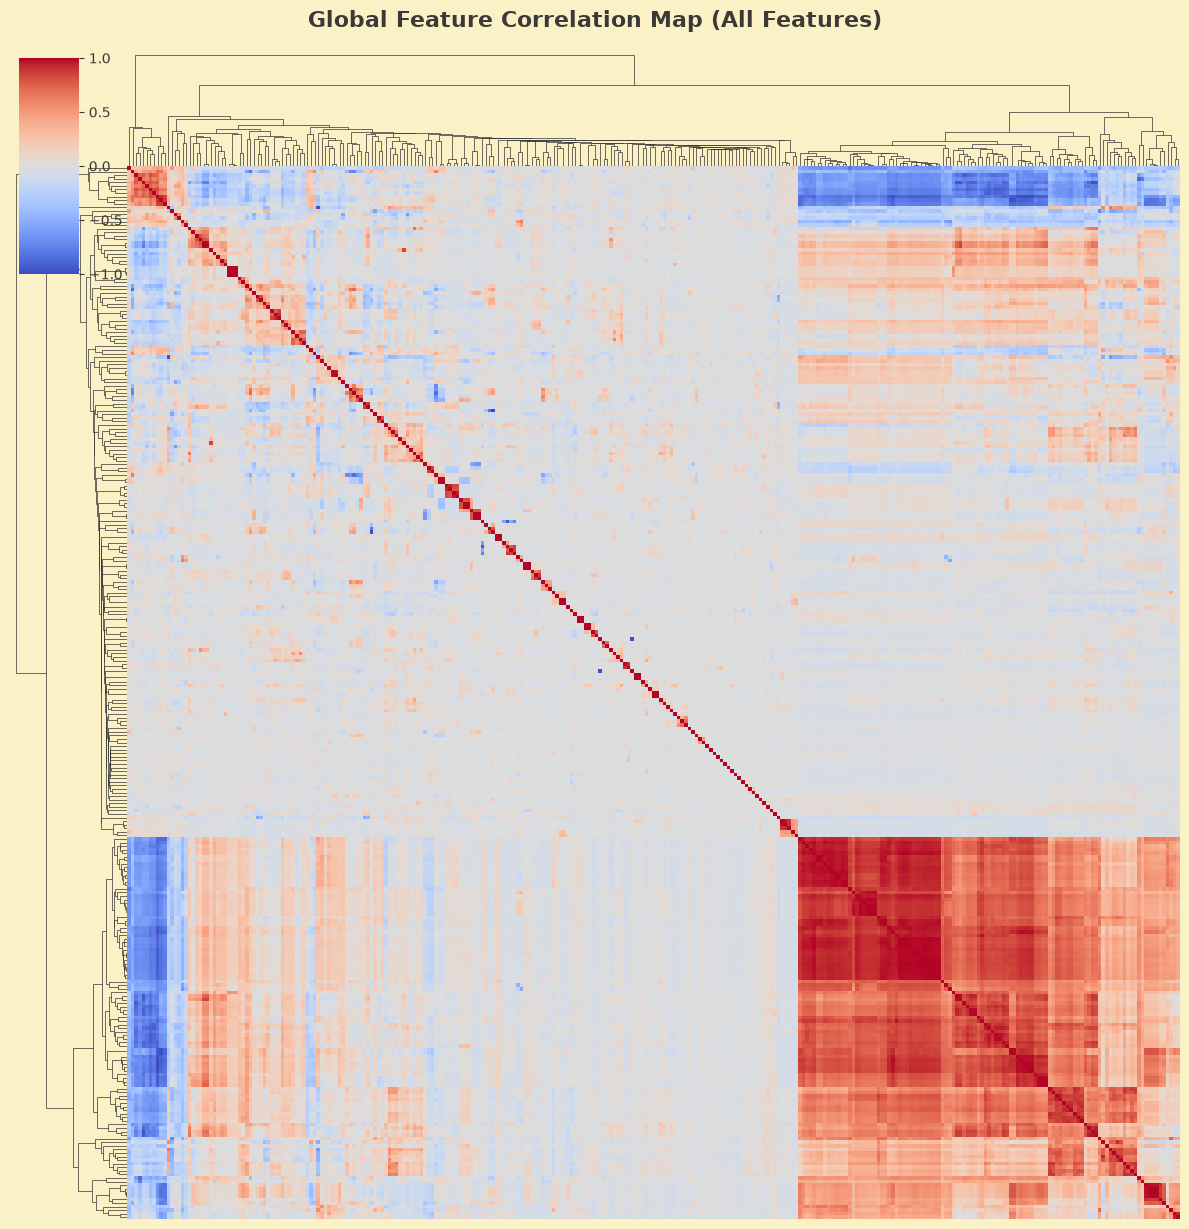

In [19]:
full_corr = X.corr()

g = sns.clustermap(full_corr, 
                   cmap="coolwarm", 
                   vmin=-1, vmax=1,
                   annot=False,        
                   xticklabels=False,  
                   yticklabels=False,  
                   figsize=(12, 12),
                   dendrogram_ratio=0.1)

g.fig.suptitle("Global Feature Correlation Map (All Features)", fontsize=16, fontweight='bold', y=1.02)
plt.show()

We can see a very interesing block of features that have strong correlation with each other. This indicates that a lot of featues are redundant, as one indicates the change in another. 

We can also see that the features that are in the red block have also a strong negative coorelation with other features. 

This may finally indicate that some kind of feature engeineering may be an optimal approach.

The dendrogram divides the features into 2 main clusters: the highly correlated ones and the grey area that does not have high correlation. Those are far more complex features. 

#### How do there high correlation feature pairs look in comparison with the features correlating with target variable?

In [20]:
HIGH_CORR_THRESHOLD = 0.80

corr_matrix = full_corr.abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# 2. Stack and filter for high correlations
stacked_corr = upper_tri.stack().reset_index()
stacked_corr.columns = ['Feature_1', 'Feature_2', 'Correlation']
high_corr_pairs = stacked_corr[stacked_corr['Correlation'] >= HIGH_CORR_THRESHOLD]

# 3. Combine both feature columns, filter for target features, and count occurrences
all_features_in_pairs = pd.concat([high_corr_pairs['Feature_1'], high_corr_pairs['Feature_2']])
target_counts = all_features_in_pairs[all_features_in_pairs.isin(top_10_cols)].value_counts()

# 4. Print results
print(f"Top 10% features that have high correlation with target variable in high-correlation \nfeatures pairs (|r| >= {HIGH_CORR_THRESHOLD}):")
if target_counts.empty:
    print("None of the target features appear in highly correlated pairs.")
else:
    for feature, count in target_counts.items():
        print(f"{feature}: {count} pair(s)")

Top 10% features that have high correlation with target variable in high-correlation 
features pairs (|r| >= 0.8):
X264: 50 pair(s)
X150: 45 pair(s)
X99: 30 pair(s)
X284: 30 pair(s)
X232: 28 pair(s)
X69: 27 pair(s)
X126: 18 pair(s)
X261: 6 pair(s)
X203: 5 pair(s)
X237: 5 pair(s)
X72: 4 pair(s)
X33: 1 pair(s)
X67: 1 pair(s)
X107: 1 pair(s)
X171: 1 pair(s)
X333: 1 pair(s)
X300: 1 pair(s)
X129: 1 pair(s)
X280: 1 pair(s)


This shows us that we can have a problem with the diluted feature importance. When using a tree boosting model it will randomly pick between X264 and its 50 highly correlated twins. This dilutes feature importance, making it look like 50 features are "weakly important" instead of recognizing that 1 feature is highly important. 

## Dimensionality reduction visualisation

In [21]:
tsne_3d = TSNE(n_components=3, perplexity=30, random_state=42, init='pca', learning_rate='auto')
X_tsne_3d = tsne_3d.fit_transform(X_scaled)

fig = px.scatter_3d(
    x=X_tsne_3d[:, 0], 
    y=X_tsne_3d[:, 1], 
    z=X_tsne_3d[:, 2],
    color=y,
    color_continuous_scale='icefire', 
    title="3D t-SNE Projection of Chemical Features",
    labels={'color': 'Solubility Target'},
    width=1000,   
    height=600    
)

fig.update_traces(marker=dict(size=4, opacity=0.7, line=dict(width=0.5, color='DarkSlateGrey')))
camera_zoom = dict(
    eye=dict(x=0.8, y=0.8, z=0.8) 
)
fig.update_layout(scene_camera=camera_zoom)
fig.show()

KeyboardInterrupt: 

In [ ]:
umap_3d = umap.UMAP(n_components=3, n_neighbors=15, min_dist=0.1, random_state=42)
X_umap_3d = umap_3d.fit_transform(X_scaled)

fig = px.scatter_3d(
    x=X_umap_3d[:, 0], 
    y=X_umap_3d[:, 1], 
    z=X_umap_3d[:, 2],
    color=y,
    color_continuous_scale='icefire', 
    title="3D UMAP Projection of Chemical Features",
    labels={'color': 'Solubility Target'},
    width=1000,   
    height=600   
)

fig.update_traces(marker=dict(size=4, opacity=0.7, line=dict(width=0.5, color='DarkSlateGrey')))
camera_zoom = dict(
    eye=dict(x=0.8, y=0.8, z=0.8) 
)
fig.update_layout(scene_camera=camera_zoom)
fig.show()

C:\Users\mary9\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


# SOME INTERPRETATION to write here

# Model

In [ ]:
X_clean = X[~results['High_Confidence_Anomaly']] #From outlier analysis
y_clean = y[~results['High_Confidence_Anomaly']]

highly_correlated = [col for col in upper_tri.columns if any(upper_tri[col] >= 0.80)]

pca_preprocessor = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95, random_state=42))
])

scenarios = {
    "0. Raw Data": {"X": X, "y": y, "preprocessor": None},
    "1. Outliers Deleted": {"X": X_clean, "y": y_clean, "preprocessor": None},
    "2. Deletion of Highly Correlated": {"X": X_clean.drop(columns=highly_correlated), "y": y_clean, "preprocessor": None},
    "3. PCA Dimensionality Reduction": {"X": X, "y": y, "preprocessor": pca_preprocessor}
}

models = {
    "XGBoost": xgb.XGBRegressor(random_state=42, objective='reg:squarederror'),
    "LightGBM": lgb.LGBMRegressor(random_state=42, verbose=-1),
    "CatBoost": CatBoostRegressor(random_state=42, verbose=False),
    "XGBoost_Huber": xgb.XGBRegressor(random_state=42, objective='reg:pseudohubererror'),
    "LightGBM_Huber": lgb.LGBMRegressor(random_state=42, objective='huber', verbose=-1)
}

def evaluate_pipeline(use_cv=True, models=models):
    results = []
    rmse_scorer = make_scorer(root_mean_squared_error, greater_is_better=False)
    cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)
    
    for method_name, config in scenarios.items():
        for model_name, model in models.items():
            steps = []
            if config["preprocessor"] is not None:
                steps.append(('preprocessor', config["preprocessor"]))
            steps.append(('model', model))
            
            pipeline = Pipeline(steps)
            
            if use_cv:
                scores = cross_val_score(
                    pipeline, config["X"], config["y"], 
                    cv=cv_strategy, scoring=rmse_scorer, n_jobs=-1
                )
                rmse = -scores.mean()
            else:
                X_tr, X_val, y_tr, y_val = train_test_split(
                    config["X"], config["y"], test_size=0.2, random_state=42
                )
                pipeline.fit(X_tr, y_tr)
                preds = pipeline.predict(X_val)
                rmse = root_mean_squared_error(y_val, preds)
                
            results.append({
                "Method": method_name,
                "Model": model_name,
                "RMSE": rmse
            })
            
    return pd.DataFrame(results)

results_df = evaluate_pipeline(use_cv=False)
comparison_table = results_df.pivot(index="Method", columns="Model", values="RMSE")

print(comparison_table)
print("\n")

best_result = results_df.loc[results_df['RMSE'].idxmin()]
print(f"Best Method: {best_result['Method']} using {best_result['Model']} (RMSE: {best_result['RMSE']:.4f})")

Model                             CatBoost  LightGBM  LightGBM_Huber  \
Method                                                                 
0. Raw Data                       0.215651  0.214650        0.214649   
1. Outliers Deleted               0.229894  0.231551        0.231551   
2. Deletion of Highly Correlated  0.232683  0.243787        0.243787   
3. PCA Dimensionality Reduction   0.229631  0.227059        0.224865   

Model                              XGBoost  XGBoost_Huber  
Method                                                     
0. Raw Data                       0.222582       0.216561  
1. Outliers Deleted               0.245185       0.254404  
2. Deletion of Highly Correlated  0.234638       0.243747  
3. PCA Dimensionality Reduction   0.254854       0.247316  


Best Method: 0. Raw Data using LightGBM_Huber (RMSE: 0.2146)


In [ ]:
print("\nWith CV:\n")
results_df_cv = evaluate_pipeline(use_cv=True, models=models)
comparison_table_cv = results_df_cv.pivot(index="Method", columns="Model", values="RMSE")

print(comparison_table_cv)
print("\n")

best_result_cv = results_df_cv.loc[results_df_cv['RMSE'].idxmin()]
print(f"Best Method: {best_result_cv['Method']} using {best_result_cv['Model']} (RMSE: {best_result_cv['RMSE']:.4f})")


With CV:



Model                             CatBoost  LightGBM  LightGBM_Huber  \
Method                                                                 
0. Raw Data                       0.217174  0.221981        0.221316   
1. Outliers Deleted               0.209623  0.215955        0.216289   
2. Deletion of Highly Correlated  0.211264  0.219989        0.219895   
3. PCA Dimensionality Reduction   0.228121  0.230278        0.229535   

Model                              XGBoost  XGBoost_Huber  
Method                                                     
0. Raw Data                       0.228309       0.226103  
1. Outliers Deleted               0.226232       0.231175  
2. Deletion of Highly Correlated  0.224363       0.223537  
3. PCA Dimensionality Reduction   0.251034       0.248617  


Best Method: 1. Outliers Deleted using CatBoost (RMSE: 0.2096)


In [ ]:
def tune_model_early_stopping(model_name, X, y, n_trials=50):
    print(f"\nStarting Optuna search for {model_name} with Early Stopping...")
    cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)
    
    def objective(trial):
        cv_scores = []
        
        # 1. Define hyperparameter spaces
        if model_name == "XGBoost":
            params = {
                'n_estimators': 2000, # High max, early stopping will cut it off
                'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
                'max_depth': trial.suggest_int('max_depth', 3, 10),
                'subsample': trial.suggest_float('subsample', 0.5, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
                'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),
                'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
                'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
                'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
                'objective': 'reg:squarederror',
                'random_state': 42,
                'early_stopping_rounds': 50
            }
        elif model_name == "LightGBM":
            params = {
                'n_estimators': 2000,
                'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
                'max_depth': trial.suggest_int('max_depth', 3, 10),
                'num_leaves': trial.suggest_int('num_leaves', 15, 255),
                'subsample': trial.suggest_float('subsample', 0.5, 1.0),
                'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
                'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
                'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
                'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
                'verbose': -1,
                'random_state': 42
            }
        elif model_name == "CatBoost":
            params = {
                'iterations': 2000,
                'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.1, log=True),
                'depth': trial.suggest_int('depth', 3, 10),
                'subsample': trial.suggest_float('subsample', 0.5, 1.0),
                'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-2, 10.0, log=True),
                'random_strength': trial.suggest_float('random_strength', 1e-8, 10.0, log=True),
                'bootstrap_type': 'Bernoulli',
                'verbose': False,
                'random_state': 42,
                'early_stopping_rounds': 50
            }

        # 2. Custom CV Loop for Early Stopping
        for train_idx, val_idx in cv_strategy.split(X):
            X_tr, X_val = (X.iloc[train_idx] if isinstance(X, pd.DataFrame) else X[train_idx], 
                           X.iloc[val_idx] if isinstance(X, pd.DataFrame) else X[val_idx])
            y_tr, y_val = (y.iloc[train_idx] if isinstance(y, pd.Series) else y[train_idx], 
                           y.iloc[val_idx] if isinstance(y, pd.Series) else y[val_idx])
            
            if model_name == "XGBoost":
                model = xgb.XGBRegressor(**params)
                model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
            
            elif model_name == "LightGBM":
                model = lgb.LGBMRegressor(**params)
                callbacks = [lgb.early_stopping(stopping_rounds=50, verbose=False)]
                model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], callbacks=callbacks)
            
            elif model_name == "CatBoost":
                model = CatBoostRegressor(**params)
                model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
                
            preds = model.predict(X_val)
            rmse = root_mean_squared_error(y_val, preds)
            cv_scores.append(rmse)
            
        return np.mean(cv_scores)

    study = optuna.create_study(direction='minimize')
    study.optimize(objective, n_trials=n_trials)
    
    print(f"[{model_name}] Best Validation RMSE: {study.best_value:.4f}")
    
    # Store params and trim arbitrary max estimators for the final stacking phase
    best_params = study.best_params
    
    # if model_name in ["XGBoost", "LightGBM"]:
    #     # We estimate a safe number of trees since stacking handles its own internal CV
    #     best_params['n_estimators'] = 800 
    # elif model_name == "CatBoost":
    #     best_params['iterations'] = 800
        
    return best_params

In [ ]:
xgb_best = tune_model_early_stopping("XGBoost", X_clean, y_clean, n_trials=50)

[I 2026-10-25 02:18:11,261] A new study created in memory with name: no-name-c0e6c5ca-9311-434e-b314-8cce10eb6ce9



Starting Optuna search for XGBoost with Early Stopping...


[I 2026-10-25 02:18:23,306] Trial 0 finished with value: 0.21337632873148174 and parameters: {'learning_rate': 0.07201331223382623, 'max_depth': 9, 'subsample': 0.6324754183382242, 'colsample_bytree': 0.5955907515211591, 'min_child_weight': 13, 'gamma': 0.005902130098583869, 'reg_alpha': 0.5195434746749787, 'reg_lambda': 3.5259290368498894e-05}. Best is trial 0 with value: 0.21337632873148174.
[I 2026-10-25 02:18:51,796] Trial 1 finished with value: 0.21069625353898438 and parameters: {'learning_rate': 0.022347557538313852, 'max_depth': 8, 'subsample': 0.8654413777447331, 'colsample_bytree': 0.9709677889236347, 'min_child_weight': 11, 'gamma': 0.0017672557663478245, 'reg_alpha': 0.0012539842599469172, 'reg_lambda': 3.517466800449923e-07}. Best is trial 1 with value: 0.21069625353898438.
[I 2026-10-25 02:19:08,164] Trial 2 finished with value: 0.2289731296267799 and parameters: {'learning_rate': 0.012843440552763598, 'max_depth': 4, 'subsample': 0.6663536069251703, 'colsample_bytree': 0

[XGBoost] Best Validation RMSE: 0.2092


In [ ]:
lgb_best = tune_model_early_stopping("LightGBM", X_clean, y_clean, n_trials=50)


[I 2026-10-25 02:59:31,510] A new study created in memory with name: no-name-b14b68bd-2626-44ea-b8a3-2005a75e47cc
C:\Users\mary9\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



Starting Optuna search for LightGBM with Early Stopping...


C:\Users\mary9\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\mary9\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\mary9\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
C:\Users\mary9\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is depreca

[LightGBM] Best Validation RMSE: 0.2095


In [ ]:
cat_best = tune_model_early_stopping("CatBoost", X_clean, y_clean, n_trials=50)

[I 2026-10-25 02:01:49,893] A new study created in memory with name: no-name-5940e0b1-c944-4b76-ada1-a9d56b442165



Starting Optuna search for CatBoost with Early Stopping...


[I 2026-10-25 02:02:03,305] Trial 0 finished with value: 0.21344191225142897 and parameters: {'learning_rate': 0.043063530679777244, 'depth': 4, 'subsample': 0.5255196358095293, 'l2_leaf_reg': 1.27838974935688, 'random_strength': 1.9040398664826692e-08}. Best is trial 0 with value: 0.21344191225142897.
[I 2026-10-25 02:02:09,961] Trial 1 finished with value: 0.21337341610685473 and parameters: {'learning_rate': 0.07752372373295524, 'depth': 4, 'subsample': 0.9556311280313132, 'l2_leaf_reg': 0.0839310826233735, 'random_strength': 0.012538467487992595}. Best is trial 1 with value: 0.21337341610685473.
[I 2026-10-25 02:05:25,580] Trial 2 finished with value: 0.21099208499115565 and parameters: {'learning_rate': 0.010013288332278217, 'depth': 7, 'subsample': 0.8447218252829425, 'l2_leaf_reg': 1.886960728771876, 'random_strength': 1.417629910814449e-05}. Best is trial 2 with value: 0.21099208499115565.
[I 2026-10-25 02:09:05,307] Trial 3 finished with value: 0.2121524057791681 and parameter

[CatBoost] Best Validation RMSE: 0.2080


In [ ]:
print(xgb_best)
print(cat_best)
print(lgb_best)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.6711639086989265, device=None,
             early_stopping_rounds=None, enable_categorical=True,
             eval_metric=None, feature_types=None, feature_weights=None,
             gamma=0.009690823994704606, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=0.008322155579602922,
             max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=10, max_leaves=None,
             min_child_weight=12, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=800, n_jobs=None,
             num_parallel_tree=None, ...)
CatBoostRegressor(depth=5, iterations=800, l2_leaf_reg=0.07632925023190759, learning_rate=0.022493454629956968, loss_function='RMSE', random_state=42, random_strength=0.38383631752285124, subsample

In [ ]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_validate

# STACKED REGRESSOR OF BEST TUNED MODELS
xgb_best = xgb.XGBRegressor(
    random_state=42, 
    objective='reg:squarederror',
    **xgb_best 
)

lgb_best = lgb.LGBMRegressor(
    random_state=42, 
    verbose=-1,
    **lgb_best
)

cat_best = CatBoostRegressor(
    random_state=42,
    verbose=False,
    **cat_best
)

# 2. Define the Stacking Regressor
base_estimators = [
    ('xgb', xgb_best),
    ('lgb', lgb_best),
    ('cat', cat_best),
]

stacking_estimator = StackingRegressor(
    estimators=base_estimators,
    final_estimator=RidgeCV(), # RidgeCV is excellent for the meta-layer
    cv=5,
    n_jobs=-1
)

stacking_pipeline = Pipeline([
    ('stack', stacking_estimator)
])

# 4. Evaluate the Stacking approach using 5-Fold CV
print("Evaluating Stacking Regressor (XGB + LGB + Cat -> RidgeCV)...")
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)
rmse_scorer = make_scorer(root_mean_squared_error, greater_is_better=False)

cv_results = cross_validate(
    stacking_pipeline, 
    X_clean, 
    y_clean, 
    cv=cv_strategy, 
    scoring=rmse_scorer, 
    return_train_score=True,
    n_jobs=-1
)

cv_train_rmse = -np.mean(cv_results['train_score'])
cv_val_rmse = -np.mean(cv_results['test_score'])

print(f"--> Stacking CV Training RMSE: {cv_train_rmse:.4f}")
print(f"--> Stacking CV Validation RMSE: {cv_val_rmse:.4f}")

# 5. Fit on the full cleaned dataset and generate final predictions
print("\nFitting Stacking Pipeline on all training data...")
stacking_pipeline.fit(X_clean, y_clean)

# Calculate exact RMSE on the full training dataset
final_train_preds = stacking_pipeline.predict(X_clean)
final_train_rmse = root_mean_squared_error(y_clean, final_train_preds)
print(f"--> Final Full Training Data RMSE: {final_train_rmse:.4f}")

# Look at the meta-model's coefficients to see which model the stack trusted the most
meta_coefs = stacking_pipeline.named_steps['stack'].final_estimator_.coef_
print("\nMeta-Model Weights:")
print(f"XGBoost:  {meta_coefs[0]:.3f}")
print(f"LightGBM: {meta_coefs[1]:.3f}")
print(f"CatBoost: {meta_coefs[2]:.3f}")

Evaluating Stacking Regressor (XGB + LGB + Cat + Linear -> RidgeCV)...
--> Stacking CV Training RMSE: 0.0660
--> Stacking CV Validation RMSE: 0.2102

Fitting Stacking Pipeline on all training data...
--> Final Full Training Data RMSE: 0.0634

Meta-Model Weights:
XGBoost:  0.208
LightGBM: 0.226
CatBoost: 0.580


The task is to create the best-performing model (using a chosen Gradient Boosting method) for predicting the dependent variable (Y), and then apply the best model to the test data.
The metric used to compare your predictions with the ground-truth targets will be RMSE.

# Testing new approach

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest, StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# 1. Load Data
training_data = pd.read_csv("../../challenge/TrainingData_Blinded.csv", header=0, index_col="Name") #[cite: 2]
training_data.rename(columns={'Y': 'target'}, inplace=True) #[cite: 2]
X = training_data.drop(columns=["target"]).copy() #[cite: 2]
y = training_data["target"] #[cite: 2]

# 2. Outlier Detection (Intersection of IsoForest & PCA+Mahalanobis)
iso_forest = IsolationForest(contamination=0.05, random_state=42) #[cite: 7]
iso_labels = iso_forest.fit_predict(X) #[cite: 7]
iso_outliers = (iso_labels == -1) #[cite: 7]

scaler = StandardScaler() #[cite: 7]
X_scaled = scaler.fit_transform(X) #[cite: 7]
pca = PCA(n_components=0.90, random_state=42) #[cite: 7]
X_pca = pca.fit_transform(X_scaled) #[cite: 7]

mahalanobis_sq = np.sum((X_pca ** 2) / pca.explained_variance_, axis=1) #[cite: 7]
mah_threshold = np.percentile(mahalanobis_sq, 95) #[cite: 7]
pca_outliers = (mahalanobis_sq > mah_threshold) #[cite: 7]

strong_anomalies = iso_outliers & pca_outliers #[cite: 7]
X_clean = X[~strong_anomalies] #[cite: 19]
y_clean = y[~strong_anomalies] #[cite: 19]

# 3. Stratified 80/10/10 Split for Continuous Target
# Binning the continuous target into 10 groups to enable stratified splitting
# bins = np.digitize(y_clean, bins=np.histogram_bin_edges(y_clean, bins=10))

# # 80% Train, 20% Temp (to be split into Val and Test)
# X_train, X_temp, y_train, y_temp, _, bins_temp = train_test_split(
#     X_clean, y_clean, bins, test_size=0.20, stratify=bins, random_state=42
# )

# # 10% Validation, 10% Test (50% of the 20% Temp split)
# X_val, X_test, y_val, y_test = train_test_split(
#     X_temp, y_temp, test_size=0.50, stratify=bins_temp, random_state=42
# )


# 3.5. Systematic 80/10/10 Split for Continuous Target
# Sort the indices of the data based on the continuous target values
sorted_indices = y_clean.sort_values().index

# Select every 10th instance for the test set (10%)
test_indices = sorted_indices[0::10]

# Select every 10th instance, offset by 1, for the validation set (10%)
val_indices = sorted_indices[1::10]

# Assign all remaining instances to the training set (80%)
train_indices = sorted_indices.difference(test_indices).difference(val_indices)

# Apply the split indices to X and y
X_train, y_train = X_clean.loc[train_indices], y_clean.loc[train_indices]
X_val,   y_val   = X_clean.loc[val_indices],   y_clean.loc[val_indices]
X_test,  y_test  = X_clean.loc[test_indices],  y_clean.loc[test_indices]



# # 4. Preprocessing Pipeline
# pca_preprocessor = Pipeline([
#     ('scaler', StandardScaler()), #[cite: 60]
#     ('pca', PCA(n_components=0.80, random_state=42)) #[cite: 60]
# ])

# 5. Define Less Complex Base Models
# Tree complexity parameters aggressively reduced compared to original tuning parameters
xgb_model = XGBRegressor(
    random_state=42, #[cite: 20]
    objective='reg:squarederror', #[cite: 20]
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,          # Reduced tree complexity 
    subsample=0.5,
    colsample_bytree=0.5,
    reg_lambda = 5.0,
    reg_alpha=1.0,
    min_child_weight=10
)


lgb_model = LGBMRegressor(
    random_state=42, #[cite: 20]
    verbose=-1, #[cite: 20]
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,          # Reduced tree complexity 
    num_leaves=15,        # Reduced node capacity 
    subsample=0.5,
    colsample_bytree=0.5,
    reg_lambda=5.0, reg_alpha=1.0,
    min_child_samples=30
)

cat_model = CatBoostRegressor(
    random_state=42, #[cite: 20]
    verbose=False, #[cite: 20]
    iterations=300,
    learning_rate=0.05,
    depth=3,               # Reduced tree complexity
    l2_leaf_reg = 10.0
)

# 6. Construct Stacking Regressor
stacking_estimator = StackingRegressor(
    estimators=[
        ('xgb', xgb_model), #[cite: 80]
        ('lgb', lgb_model), #[cite: 80]
        ('cat', cat_model)  #[cite: 59]
    ],
    final_estimator=RidgeCV(), #[cite: 80]
    cv=5, #[cite: 80]
    n_jobs=-1 #[cite: 80]
)

final_pipeline = Pipeline([
    ('stack', stacking_estimator) #[cite: 81]
])

# 7. Train and Evaluate Pipeline
final_pipeline.fit(X_train, y_train)

# Calculate RMSE on Train, Validation, and Test partitions
train_preds = final_pipeline.predict(X_train)
val_preds = final_pipeline.predict(X_val)
test_preds = final_pipeline.predict(X_test)

print(f"Train RMSE: {root_mean_squared_error(y_train, train_preds):.4f}")
print(f"Validation RMSE: {root_mean_squared_error(y_val, val_preds):.4f}")
print(f"Test RMSE: {root_mean_squared_error(y_test, test_preds):.4f}")

Train RMSE: 0.1458
Validation RMSE: 0.1980
Test RMSE: 0.2139


In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import f_oneway
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import RidgeCV
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sqlalchemy import column
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import lightgbm as lgb
from sklearn.linear_model import LinearRegression

# 1. Load Data
training_data = pd.read_csv("../../challenge/TrainingData_Blinded.csv", header=0, index_col="Name")
training_data.rename(columns={'Y': 'target'}, inplace=True)
X = training_data.drop(columns=["target"]).copy()
y = training_data["target"].copy()

# 2. Systematic 80/10/10 Split FIRST (Prevents Data Leakage!)
sorted_indices = y.sort_values().index
test_indices = sorted_indices[0::10]
val_indices = sorted_indices[1::10]
train_indices = sorted_indices.difference(test_indices).difference(val_indices)

X_train_raw, y_train = X.loc[train_indices].copy(), y.loc[train_indices].copy()
X_val_raw,   y_val   = X.loc[val_indices].copy(),   y.loc[val_indices].copy()
X_test_raw,  y_test  = X.loc[test_indices].copy(),  y.loc[test_indices].copy()

# 3. Outlier Detection Fit ONLY on Train (Applied to Train)
iso = IsolationForest(contamination=0.05, random_state=42)
iso_outliers = (iso.fit_predict(X_train_raw) == -1)

scaler_out = StandardScaler()
X_tr_sc = scaler_out.fit_transform(X_train_raw)
pca_out = PCA(n_components=0.90, random_state=42)
X_tr_pca = pca_out.fit_transform(X_tr_sc)

mah_sq = np.sum((X_tr_pca ** 2) / pca_out.explained_variance_, axis=1)
mah_outliers = mah_sq > np.percentile(mah_sq, 95)

clean_mask = ~(iso_outliers & mah_outliers)
X_train_raw = X_train_raw.loc[clean_mask].copy()
y_train = y_train.loc[clean_mask].copy()

# 4. Feature Identification & ANOVA Pruning (Fit on X_train_raw only)
variances = X_train_raw.var()
low_var_cols = variances[variances < 0.01].index.tolist()

important_low_var = []
for col in low_var_cols:
    g0 = y_train[X_train_raw[col] == 0]
    g1 = y_train[X_train_raw[col] != 0]
    if len(g0) > 2 and len(g1) > 2:
        _, p_val = f_oneway(g0, g1)
        if p_val < 0.05:
            important_low_var.append(col)

# Drop the ~129 dead low-variance features that fail the ANOVA test
dead_low_var = [c for c in low_var_cols if c not in important_low_var]
X_train_pruned = X_train_raw.drop(columns=dead_low_var)
X_val_pruned   = X_val_raw.drop(columns=dead_low_var)
X_test_pruned  = X_test_raw.drop(columns=dead_low_var)

# Identify binary features and top correlating features on Train
binary_cols = [c for c in X_train_pruned.columns if X_train_pruned[c].nunique() <= 2]
corrs = X_train_pruned.corrwith(y_train).abs()
top30_cols = corrs.nlargest(30).index.tolist()

def engineer_chemistry_features(df):
    d = df.copy()
    # Sparsity / Zero-inflation counters based on EDA
    d['active_binary_sum'] = d[binary_cols].sum(axis=1)
    d['active_anova_count'] = (d[important_low_var] != 0).sum(axis=1)
    d['active_top30_count'] = (d[top30_cols] != 0).sum(axis=1)
    
    # Explicit interactions between top positive (X107, X33, X67) & negative (X171, X133, X280) drivers
    if {'X107', 'X171', 'X133', 'X33', 'X280'}.issubset(d.columns):
        d['inter_X107_minus_X171'] = d['X107'] - d['X171']
        d['inter_X107_prod_X171']  = d['X107'] * d['X171']
        d['inter_X33_minus_X133']  = d['X33'] - d['X133']
        d['inter_pos_sum'] = d['X107'] + d['X33'] 
        d['inter_neg_sum'] = d['X171'] + d['X133'] + d['X280']
        d['inter_net_driver'] = d['inter_pos_sum'] - d['inter_neg_sum']
    return d

X_tr_fe = engineer_chemistry_features(X_train_pruned)
X_va_fe = engineer_chemistry_features(X_val_pruned)
X_te_fe = engineer_chemistry_features(X_test_pruned)

# 5. Selective PCA ONLY on the Redundant Collinear Block (|r| >= 0.80)
corr_matrix = X_tr_fe.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
highly_correlated = [col for col in upper_tri.columns if any(upper_tri[col] >= 0.80)]
independent_features = [col for col in X_tr_fe.columns if col not in highly_correlated]

selective_preprocessor = ColumnTransformer(
    transformers=[
        ('pca_redundant', Pipeline([
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=0.95, random_state=42))
        ]), highly_correlated),
        ('passthrough_indep', 'passthrough', independent_features)
    ]
)

X_tr_proc = selective_preprocessor.fit_transform(X_tr_fe)
X_va_proc = selective_preprocessor.transform(X_va_fe)
X_te_proc = selective_preprocessor.transform(X_te_fe)

# 6. 5-Fold Out-of-Fold Early-Stopped Training
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# FIX 1: Change to 2 columns
oof_preds = np.zeros((len(X_tr_proc), 2))
val_preds_folds = np.zeros((len(X_va_proc), 2))
test_preds_folds = np.zeros((len(X_te_proc), 2))
train_preds_folds = np.zeros((len(X_tr_proc), 2))

for fold, (tr_idx, va_idx) in enumerate(kf.split(X_tr_proc)):
    X_f_tr, y_f_tr = X_tr_proc[tr_idx], y_train.iloc[tr_idx]
    X_f_va, y_f_va = X_tr_proc[va_idx], y_train.iloc[va_idx]
    
    xgb_m = XGBRegressor(
        n_estimators=1500, learning_rate=0.02, max_depth=4,
        subsample=0.6, colsample_bytree=0.6, colsample_bynode=0.3,
        min_child_weight=10, reg_alpha=0.5, reg_lambda=5.0,
        objective='reg:squarederror', early_stopping_rounds=40, random_state=42 + fold
    )
    
    cat_m = CatBoostRegressor(
        iterations=1500, learning_rate=0.025, depth=5,
        l2_leaf_reg=8.0, random_strength=5.0, subsample=0.7,
        bootstrap_type='Bernoulli', early_stopping_rounds=40,
        verbose=False, random_state=42 + fold
    )
    
    xgb_m.fit(X_f_tr, y_f_tr, eval_set=[(X_f_va, y_f_va)], verbose=False)
    cat_m.fit(X_f_tr, y_f_tr, eval_set=[(X_f_va, y_f_va)], verbose=False)
    
    # FIX 2: Store XGB at index 0 and CatBoost at index 1
    oof_preds[va_idx, 0] = xgb_m.predict(X_f_va)
    oof_preds[va_idx, 1] = cat_m.predict(X_f_va)
    
    # Accumulate fold-averaged predictions 
    for i, m in enumerate([xgb_m, cat_m]):
        train_preds_folds[:, i] += m.predict(X_tr_proc) / kf.n_splits
        val_preds_folds[:, i]   += m.predict(X_va_proc) / kf.n_splits
        test_preds_folds[:, i]  += m.predict(X_te_proc) / kf.n_splits

# 7. Fit RidgeCV on Out-of-Fold Predictions
# meta_model = RidgeCV(alphas=np.logspace(-2, 3, 50))
# meta_model.fit(oof_preds, y_train)
meta_model = LinearRegression(positive=True)
meta_model.fit(oof_preds, y_train)

final_train_preds = meta_model.predict(train_preds_folds)
final_val_preds   = meta_model.predict(val_preds_folds)
final_test_preds  = meta_model.predict(test_preds_folds)

print(f"OOF CV RMSE:     {root_mean_squared_error(y_train, meta_model.predict(oof_preds)):.4f}")
print(f"Train RMSE:      {root_mean_squared_error(y_train, final_train_preds):.4f}")
print(f"Validation RMSE: {root_mean_squared_error(y_val, final_val_preds):.4f}")
print(f"Test RMSE:       {root_mean_squared_error(y_test, final_test_preds):.4f}")
print(f"Blender Weights (XGB, Cat): {np.round(meta_model.coef_, 2)}")

OOF CV RMSE:     0.2173
Train RMSE:      0.1448
Validation RMSE: 0.2035
Test RMSE:       0.2452
Blender Weights (XGB, Cat): [0.44 0.64]


In [ ]:
# 1. Load Data
training_data = pd.read_csv("../../challenge/TrainingData_Blinded.csv", header=0) #[cite: 2]
training_data.rename(columns={'Y': 'target'}, inplace=True)
X = training_data.drop(columns=["target"]).copy()
y = training_data["target"].copy()

# 2. Global Outlier Removal
iso = IsolationForest(contamination=0.05, random_state=42) #[cite: 7]
iso_outliers = (iso.fit_predict(X) == -1)

scaler_out = StandardScaler() #[cite: 7]
X_pca_sc = scaler_out.fit_transform(X)
pca_out = PCA(n_components=0.90, random_state=42) #[cite: 7]
X_pca_trans = pca_out.fit_transform(X_pca_sc)

mah_sq = np.sum((X_pca_trans ** 2) / pca_out.explained_variance_, axis=1) #[cite: 7]
mah_outliers = mah_sq > np.percentile(mah_sq, 95)

clean_mask = ~(iso_outliers & mah_outliers) #[cite: 7]
X_clean = X.loc[clean_mask].copy()
y_clean = y.loc[clean_mask].copy()

In [ ]:
# 3. Binned Stratified 80/10/10 Split
# Quantile bins keep approximately equal-sized groups and avoid singleton edge bins.
bins = pd.qcut(y_clean, q=5, labels=False, duplicates="drop")

X_train_raw, X_temp, y_train, y_temp, _, bins_temp = train_test_split(
    X_clean, y_clean, bins, test_size=0.20, stratify=bins, random_state=42
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=bins_temp, random_state=42
)

In [ ]:
import mlflow

# Change this value to create or resume a different MLflow experiment.
EXPERIMENT_NAME = "solubility-challenge"
MLFLOW_TRACKING_URI = "sqlite:///mlflow.db"
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(EXPERIMENT_NAME)
import numpy as np
import pandas as pd
from scipy.stats import f_oneway
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

# 1. Load Data & Global Outlier Removal
training_data = pd.read_csv("../../challenge/TrainingData_Blinded.csv", header=0, index_col="Name") #[cite: 2]
training_data.rename(columns={'Y': 'target'}, inplace=True)
X = training_data.drop(columns=["target"]).copy()
y = training_data["target"].copy()

iso = IsolationForest(contamination=0.05, random_state=42) #[cite: 7]
iso_outliers = (iso.fit_predict(X) == -1)

scaler_out = StandardScaler() #[cite: 7]
X_pca_sc = scaler_out.fit_transform(X)
pca_out = PCA(n_components=0.90, random_state=42) #[cite: 7]
X_pca_trans = pca_out.fit_transform(X_pca_sc)

mah_sq = np.sum((X_pca_trans ** 2) / pca_out.explained_variance_, axis=1) #[cite: 7]
mah_outliers = mah_sq > np.percentile(mah_sq, 95)

clean_mask = ~(iso_outliers & mah_outliers) #[cite: 7]
X_clean = X.loc[clean_mask].copy()
y_clean = y.loc[clean_mask].copy()

# 2. Binned Stratified 80/10/10 Split
# Quantile bins keep approximately equal-sized groups and avoid singleton edge bins.
bins = pd.qcut(y_clean, q=5, labels=False, duplicates="drop")

X_train_raw, X_temp, y_train, y_temp, _, bins_temp = train_test_split(
    X_clean, y_clean, bins, test_size=0.20, stratify=bins, random_state=42
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=bins_temp, random_state=42
)

# 3. Feature Identification & ANOVA Pruning (Fit on X_train_raw only)
variances = X_train_raw.var()
low_var_cols = variances[variances < 0.01].index.tolist() #[cite: 8]

important_low_var = []
for col in low_var_cols:
    g0 = y_train[X_train_raw[col] == 0]
    g1 = y_train[X_train_raw[col] != 0]
    if len(g0) > 2 and len(g1) > 2:
        _, p_val = f_oneway(g0, g1) #[cite: 9]
        if p_val < 0.05:
            important_low_var.append(col)

dead_low_var = [c for c in low_var_cols if c not in important_low_var]
X_train_pruned = X_train_raw.drop(columns=dead_low_var)
X_val_pruned   = X_val_raw.drop(columns=dead_low_var)
X_test_pruned  = X_test_raw.drop(columns=dead_low_var)

binary_cols = [c for c in X_train_pruned.columns if X_train_pruned[c].nunique() <= 2]
corrs = X_train_pruned.corrwith(y_train).abs()
top30_cols = corrs.nlargest(30).index.tolist()

def engineer_chemistry_features(df):
    d = df.copy()
    d['active_binary_sum'] = d[binary_cols].sum(axis=1)
    d['active_anova_count'] = (d[important_low_var] != 0).sum(axis=1)
    d['active_top30_count'] = (d[top30_cols] != 0).sum(axis=1)
    
    if {'X107', 'X171', 'X133', 'X33', 'X280'}.issubset(d.columns):
        d['inter_X107_minus_X171'] = d['X107'] - d['X171']
        d['inter_X107_prod_X171']  = d['X107'] * d['X171']
        d['inter_X33_minus_X133']  = d['X33'] - d['X133']
        d['inter_pos_sum'] = d['X107'] + d['X33']
        d['inter_neg_sum'] = d['X171'] + d['X133'] + d['X280']
        d['inter_net_driver'] = d['inter_pos_sum'] - d['inter_neg_sum']
    return d

X_tr_fe = engineer_chemistry_features(X_train_pruned)
X_va_fe = engineer_chemistry_features(X_val_pruned)
X_te_fe = engineer_chemistry_features(X_test_pruned)

# 4. Selective PCA ONLY on the Redundant Collinear Block (|r| >= 0.80)
corr_matrix = X_tr_fe.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
highly_correlated = [col for col in upper_tri.columns if any(upper_tri[col] >= 0.80)] #[cite: 17]
independent_features = [col for col in X_tr_fe.columns if col not in highly_correlated]

selective_preprocessor = ColumnTransformer(
    transformers=[
        ('pca_redundant', Pipeline([
            ('scaler', StandardScaler()),
            ('pca', PCA(n_components=0.95, random_state=42))
        ]), highly_correlated),
        ('passthrough_indep', 'passthrough', independent_features)
    ]
)

X_tr_proc = selective_preprocessor.fit_transform(X_tr_fe)
X_va_proc = selective_preprocessor.transform(X_va_fe)
X_te_proc = selective_preprocessor.transform(X_te_fe)

# 5. Define Individual Models
xgb_model = XGBRegressor(
    n_estimators=1500, learning_rate=0.02, max_depth=3,
    subsample=0.6, colsample_bytree=0.6, colsample_bynode=0.3,
    min_child_weight=15, reg_alpha=0.5, reg_lambda=5.0,
    objective='reg:squarederror', random_state=42
)

cat_model = CatBoostRegressor(
    iterations=1500, learning_rate=0.025, depth=4,
    l2_leaf_reg=8.0, random_strength=5.0, subsample=0.7,
    bootstrap_type='Bernoulli', verbose=False, random_state=42
)

# 6. Train, evaluate, and track both models in one MLflow run
with mlflow.start_run(run_name="xgb-catboost-validation"):
    mlflow.set_tags({
        "dataset": "TrainingData_Blinded.csv",
        "split": "80/10/10 quantile-stratified",
    })
    mlflow.log_params({
        "random_state": 42,
        "n_features_before_pca": X.shape[1],
        "n_features_after_pca": X_tr_proc.shape[1],
        "n_train": len(y_train),
        "n_validation": len(y_val),
        "n_test": len(y_test),
        "xgb_n_estimators": xgb_model.get_params()["n_estimators"],
        "xgb_max_depth": xgb_model.get_params()["max_depth"],
        "cat_iterations": cat_model.get_params()["iterations"],
        "cat_depth": cat_model.get_params()["depth"],
    })


    print("Training XGBoost...")
    xgb_model.fit(
        X_tr_proc, y_train,
        eval_set=[(X_va_proc, y_val)],
        early_stopping_rounds=40, #[cite: 23]
        verbose=False
    )

    print("Training CatBoost...")
    cat_model.fit(
        X_tr_proc, y_train,
        eval_set=[(X_va_proc, y_val)],
        early_stopping_rounds=40, #[cite: 23]
        verbose=False
    )

    xgb_metrics = {
        "xgb_train_rmse": root_mean_squared_error(y_train, xgb_model.predict(X_tr_proc)),
        "xgb_validation_rmse": root_mean_squared_error(y_val, xgb_model.predict(X_va_proc)),
        "xgb_test_rmse": root_mean_squared_error(y_test, xgb_model.predict(X_te_proc)),
    }
    cat_metrics = {
        "cat_train_rmse": root_mean_squared_error(y_train, cat_model.predict(X_tr_proc)),
        "cat_validation_rmse": root_mean_squared_error(y_val, cat_model.predict(X_va_proc)),
        "cat_test_rmse": root_mean_squared_error(y_test, cat_model.predict(X_te_proc)),
    }
    mlflow.log_metrics({**xgb_metrics, **cat_metrics})

# 7. Print the tracked results
print("\n--- XGBoost Performance ---")
print(f"Train RMSE:      {xgb_metrics['xgb_train_rmse']:.4f}")
print(f"Validation RMSE: {xgb_metrics['xgb_validation_rmse']:.4f}")
print(f"Test RMSE:       {xgb_metrics['xgb_test_rmse']:.4f}")

print("\n--- CatBoost Performance ---")
print(f"Train RMSE:      {cat_metrics['cat_train_rmse']:.4f}")
print(f"Validation RMSE: {cat_metrics['cat_validation_rmse']:.4f}")
print(f"Test RMSE:       {cat_metrics['cat_test_rmse']:.4f}")



2026/10/26 05:32:25 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/26 05:32:25 INFO mlflow.store.db.utils: Updating database tables
2026/10/26 05:32:27 INFO mlflow.tracking.fluent: Experiment with name 'solubility-challenge' does not exist. Creating a new experiment.


Training XGBoost...


TypeError: XGBModel.fit() got an unexpected keyword argument 'early_stopping_rounds'